# 02 · The Four-Criteria Validation Protocol

*Feature validation workstream.*

`PROPOSAL.md` § 4.3 requires every feature claim to pass **four criteria** (Bricken et al., 2023) before
it counts as a real, validated feature, not just "a direction that seems to correlate with something":

1. **Specificity**: the feature is active in the target context, and mostly *not* active elsewhere.
2. **Sensitivity**: the target context reliably activates it (not just sometimes).
3. **Causal effect**: intervening on the feature changes downstream behavior in the expected way.
4. **Non-correspondence to any single neuron**: it's a genuine direction in activation space, not just
   one dimension of the original model relabeled.

This notebook walks through all four, by hand, on a toy feature from a toy SAE. Treat the *conclusions*
as illustrative, not as real interpretability findings: twenty short sentences and 300 training epochs
aren't enough data to responsibly claim anything about GPT-2's internals. The point is to internalize the
checklist you'll actually run for real once you're doing this on real data.


## Setup

This repeats the same handful of lines from `00_environment_and_activations.ipynb` (load the model,
grab a batch of residual-stream activations) so this notebook stands on its own. If you've already been
through notebook 00, this will feel familiar.


In [1]:
import torch
from transformer_lens import HookedTransformer

torch.manual_seed(0)
model = HookedTransformer.from_pretrained("gpt2", device="cpu")
LAYER = 6

# a small, varied set of short prompts, plenty for a toy demo, not for a real result
PROMPTS = [
    "The capital of France is Paris.",
    "The capital of Germany is Berlin.",
    "Two plus two equals four.",
    "Three plus three equals six.",
    "The sky is blue on a clear day.",
    "The ocean is deep and blue.",
    "The cat sat on the warm mat.",
    "The dog slept on the soft rug.",
    "Water boils at one hundred degrees.",
    "Ice melts at zero degrees.",
    "The sun rises in the east.",
    "The moon orbits the Earth.",
    "She opened the old wooden door.",
    "He closed the heavy metal gate.",
    "The train arrived at the station.",
    "The plane landed on the runway.",
    "Paris is the capital of France.",
    "Berlin is the capital of Germany.",
    "Five minus two equals three.",
    "Ten divided by two equals five.",
]

activations = []
with torch.no_grad():
    for p in PROMPTS:
        _, cache = model.run_with_cache(model.to_tokens(p))
        resid = cache[f"blocks.{LAYER}.hook_resid_post"][0]  # (position, d_model)
        activations.append(resid[1:])  # drop position 0, the prepended BOS token (an outlier "attention sink")

X = torch.cat(activations, dim=0)  # (total_tokens, d_model)
print(f"activation matrix X: {tuple(X.shape)}  (total_tokens, d_model)")


/tmp/ipykernel_5181/3855573954.py:5: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device="cpu")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2 into HookedTransformer


activation matrix X: (140, 768)  (total_tokens, d_model)


In [2]:
import torch.nn as nn

class ToySAE(nn.Module):
    def __init__(self, d_model, dict_size):
        super().__init__()
        self.W_enc = nn.Parameter(torch.randn(d_model, dict_size) * 0.01)
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        self.W_dec = nn.Parameter(torch.randn(dict_size, d_model) * 0.01)
        self.b_dec = nn.Parameter(torch.zeros(d_model))

    def encode(self, x):
        return torch.relu((x - self.b_dec) @ self.W_enc + self.b_enc)

    def decode(self, f):
        return f @ self.W_dec + self.b_dec

    def forward(self, x):
        f = self.encode(x)
        x_hat = self.decode(f)
        return f, self.decode(f)

sae = ToySAE(d_model=X.shape[1], dict_size=128)
opt = torch.optim.Adam(sae.parameters(), lr=1e-3)
for _ in range(300):
    opt.zero_grad()
    f, x_hat = sae(X)
    loss = ((x_hat - X) ** 2).mean() + 1e-3 * f.abs().mean()
    loss.backward()
    opt.step()

with torch.no_grad():
    F = sae.encode(X)  # (total_tokens, dict_size) feature activations for every token we cached
print("feature activations:", tuple(F.shape))


feature activations: (140, 128)


## Pick a feature to examine

We want one that's neither dead (never fires) nor firing on everything. A reasonable middle ground:
active on somewhere between 5% and 50% of tokens.


In [3]:
with torch.no_grad():
    active_frac = (F > 1e-6).float().mean(dim=0)  # fraction of tokens each feature fires on

candidates = ((active_frac > 0.05) & (active_frac < 0.5)).nonzero().squeeze(-1)
feature_idx = candidates[0].item() if len(candidates) > 0 else int(active_frac.argmax())
print(f"examining feature #{feature_idx}, active on {active_frac[feature_idx]:.1%} of tokens")


examining feature #16, active on 32.1% of tokens


## 1 & 2. Specificity and sensitivity

Let's see which *tokens* activate this feature most, and whether it fires reliably within a topic. We
built our toy dataset with two loose "topics" mixed together (geography/capitals and arithmetic), a
specific, sensitive feature should show a clear pattern across the two.


In [4]:
# reconstruct which prompt & token each row of X/F came from
token_labels = []
for p in PROMPTS:
    for tok in model.to_str_tokens(p)[1:]:  # skip BOS, matching the SETUP_CODE activation cache above
        token_labels.append((p, tok))

with torch.no_grad():
    activation_values = F[:, feature_idx]

top_k = activation_values.topk(8)
print(f"Top activating tokens for feature #{feature_idx}:")
for val, idx in zip(top_k.values, top_k.indices):
    prompt, tok = token_labels[idx.item()]
    print(f"  {val.item():.3f}   {tok!r:10s}  (from: {prompt!r})")


Top activating tokens for feature #16:
  59.609   ' capital'  (from: 'The capital of France is Paris.')
  59.609   ' capital'  (from: 'The capital of Germany is Berlin.')
  55.283   ' capital'  (from: 'Berlin is the capital of Germany.')
  54.709   ' capital'  (from: 'Paris is the capital of France.')
  30.589   ' east'     (from: 'The sun rises in the east.')
  22.216   ' runway'   (from: 'The plane landed on the runway.')
  19.706   ' station'  (from: 'The train arrived at the station.')
  19.029   ' ocean'    (from: 'The ocean is deep and blue.')


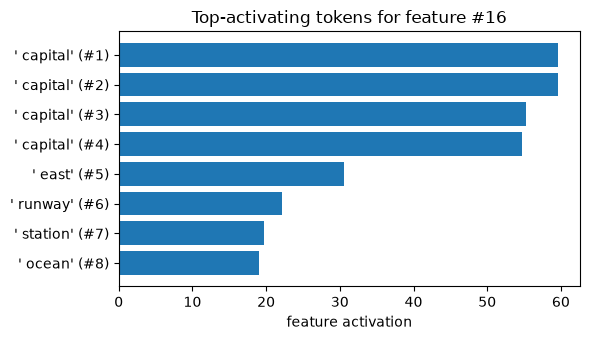

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
bar_labels = [f"{token_labels[idx.item()][1]!r} (#{rank})" for rank, idx in enumerate(top_k.indices, start=1)]
y_pos = range(len(bar_labels))
ax.barh(list(y_pos)[::-1], top_k.values.tolist())
ax.set_yticks(list(y_pos)[::-1])
ax.set_yticklabels(bar_labels)
ax.set_xlabel("feature activation")
ax.set_title(f"Top-activating tokens for feature #{feature_idx}")
plt.tight_layout()
plt.show()


Look at whether the top activations cluster around one kind of content (e.g., mostly numbers, or mostly
place names), that clustering *is* specificity. If they instead look scattered across unrelated
prompts, this particular feature likely isn't specific to anything interpretable, which is a completely
normal outcome on a toy SAE this small, and worth noticing rather than explaining away.


## 3. Causal effect

If the feature really represents something the model uses, zeroing it out for a token where it's
strongly active should change that position's reconstructed activation, and, once patched back into the
model, its predictions too. We check the more local version here: how much does the reconstruction change
when we ablate just this one feature?


In [6]:
with torch.no_grad():
    most_active_row = activation_values.argmax().item()
    x = X[most_active_row : most_active_row + 1]

    f_full = sae.encode(x)
    x_hat_full = sae.decode(f_full)

    f_ablated = f_full.clone()
    f_ablated[0, feature_idx] = 0.0
    x_hat_ablated = sae.decode(f_ablated)

    shift = (x_hat_full - x_hat_ablated).norm().item()
    baseline = x_hat_full.norm().item()

print(f"reconstruction shift from ablating feature #{feature_idx}: {shift:.4f}")
print(f"(for scale, the full reconstruction's norm is {baseline:.4f}, so the shift is {shift / baseline:.1%} of it)")


reconstruction shift from ablating feature #16: 53.9883
(for scale, the full reconstruction's norm is 96.7701, so the shift is 55.8% of it)


A feature with a real causal role should shift the reconstruction by a non-trivial fraction of its norm
when ablated. A feature that barely changes anything when zeroed out isn't pulling its weight, which is
itself a useful (negative) result, not a failure of the exercise.


## 4. Non-correspondence to any single neuron

Finally: is this "feature" secretly just one original activation dimension relabeled? We check by
looking at the feature's decoder direction (its "meaning" in activation space) and asking whether it
points mostly along a single axis, or is spread across many.


In [7]:
with torch.no_grad():
    decoder_direction = sae.W_dec[feature_idx]  # (d_model,): this feature's direction in activation space
    normalized = decoder_direction / decoder_direction.norm()
    max_component = normalized.abs().max().item()

print(f"largest single component of the decoder direction (as a fraction of its total norm): {max_component:.3f}")
print("(close to 1.0 would mean it's really just one neuron; a spread-out direction stays well below that)")


largest single component of the decoder direction (as a fraction of its total norm): 0.150
(close to 1.0 would mean it's really just one neuron; a spread-out direction stays well below that)


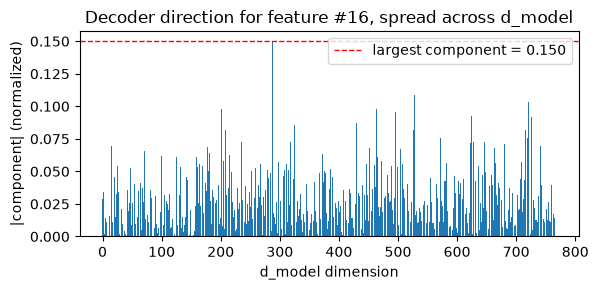

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(len(normalized)), normalized.abs().tolist())
ax.axhline(max_component, color="red", linestyle="--", linewidth=1,
           label=f"largest component = {max_component:.3f}")
ax.set_xlabel("d_model dimension")
ax.set_ylabel("|component| (normalized)")
ax.set_title(f"Decoder direction for feature #{feature_idx}, spread across d_model")
ax.legend()
plt.tight_layout()
plt.show()


## What you should take away

- All four criteria are checkable with code you already know how to write: top-activating examples
  (specificity/sensitivity), a before/after ablation (causal effect), and a look at the decoder weight
  vector (non-neuron correspondence).
- None of these checks are automatically trustworthy on their own; that's *why* the protocol requires
  all four together, not just whichever one gives the answer you were hoping for.
- On real data, you'd do this with far more examples, hold-out prompts, and quantitative thresholds, not
  eyeballing eight numbers. This notebook is the shape of the real check, not the real check.
